In [47]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.integrate as sp
import math as mt
from scipy.integrate import solve_ivp

In [49]:
def Gamma(d): #Define Gamma function as numerical integral
    result, _ = sp.quad(lambda t: t**(d-1)*np.exp(-t), 0, np.inf) #returns only numerical value, _ "deletes" the error value from sp.quad!
    return result

In [50]:
#coupled deq derived from wetterich eq
def flow(k, S, d, rho): #del_t Gamma_k = ...
    mq , l = S #mq = m², l = lambda

    prefactor = (2*k**(d+1))/((4*np.pi)**(d/2)*Gamma(d/2 + 1))
 
    dldk = (prefactor*((2*l**2) / (k**2 +mq + l*rho)**3 + (18*l**2) / (k**2 +mq + 3*l*rho)**3)
      )  #dlambda/dk
    
    dmqdk = (prefactor*(-l / (k**2 + mq + l*rho)**2 - 3*l / (k**2 + mq + 3*l*rho)**2 ) - rho*dldk
      )  #dm²/dk

    return [dmqdk, dldk]

In [82]:
#initial conditions
d = 3.0
rho = 50.0
mq0 = 16.0
l0 = 0.0001
k0 = 1000.0
k_end = 0.0

S0 = [mq0, l0]

k = np.linspace(k0, k_end, 1000)

sol = solve_ivp(flow, t_span=(max(k), min(k)), y0=S0, t_eval=k, method='RK45', args= (d, rho))

#if sol.success:
#    print("Integration successful")
#else:
#    print("Integration failed:", sol.message)

In [83]:
k_vals = sol.t
mq_vals = sol.y[0]
l_vals = sol.y[1]

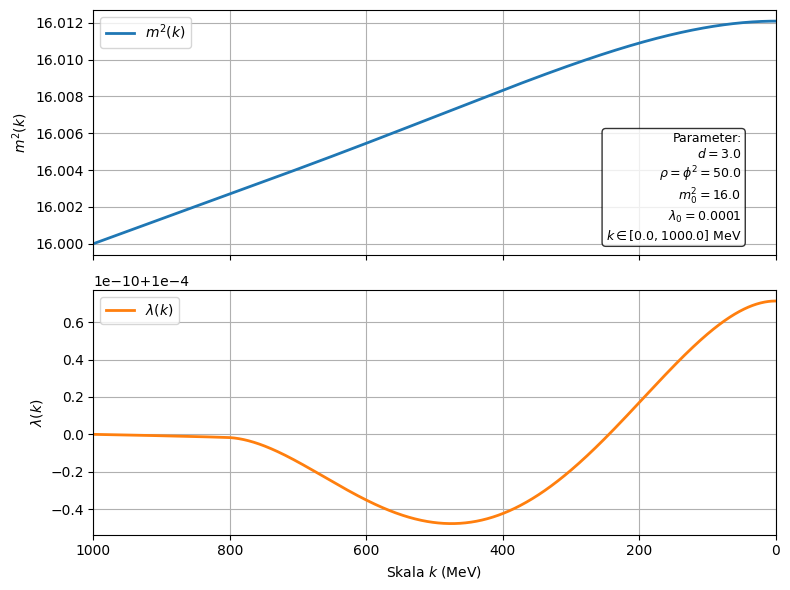

In [87]:
# Plotting
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

ax1.plot(k_vals, mq_vals, color='tab:blue', lw=2, label=r'$m^2(k)$')
ax1.set_ylabel(r'$m^2(k)$')
ax1.grid(True)
ax1.legend(loc='upper left')

ax2.plot(k_vals, l_vals, color='tab:orange', lw=2, label=r'$\lambda(k)$')
ax2.set_xlabel(r'Skala $k$ (MeV)')
ax2.set_ylabel(r'$\lambda(k)$')
ax2.grid(True)
ax2.legend(loc='upper left')

# Zentrale Parameter-Box unten rechts im oberen Plot (ax1)
param_text = (
    f"Parameter:\n"
    f"$d = {d}$\n"
    f"$\\rho = \\phi^2 = {rho}$\n"
    f"$m_0^2 = {mq0}$\n"
    f"$\\lambda_0 = {l0}$\n"
    f"$k \\in [{k_end}, {k0}]$ MeV"
)
ax1.text(0.95, 0.05, param_text, transform=ax1.transAxes, fontsize=9,
         horizontalalignment='right', verticalalignment='bottom',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax1.set_xlim(k0, k_end)

plt.tight_layout()
plt.show()